# ZTF reference catalogs vs Pan-STARRS: matching and filtering, quadrant 643_11_1

ZTF side: IRSA's DAOPhot PSF catalogs of the three deep reference images (`refpsfcat`), merged into objects by mutual nearest neighbour at 1". PS1 side: the DR2 stack-object catalog for the quadrant. The two are matched the same way. Tables were built on 2026-11-11 and live in `Data/ztf_data/`.

## 1. Setup

In [1]:
import glob, os, sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
from scipy.ndimage import distance_transform_edt
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy.visualization import simple_norm
import astropy.units as u
from Extracting.images import load_ztf_refimg, load_ps1_skycell
from Extracting.ztf_images import refimg_path

D = '../Data'
obj = pd.read_parquet(f'{D}/ztf_data/ztfobj_643_11_1.parquet')      # one row per merged ZTF object
ps1 = pd.read_parquet(f'{D}/ztf_data/ps1_643_11_1.parquet')         # PS1 objects on valid ZTF pixels; obj.ps1_idx indexes this
ztf_cat = {b: pd.read_parquet(f'{D}/ztf_data/ztfpsf_643_11_1_{b}.parquet') for b in 'gri'}   # per-band DAOPhot catalogs
cosd = np.cos(np.radians(ps1.dec.median()))

obj['matched'] = obj.ps1_idx >= 0
ps1['matched'] = np.isin(np.arange(len(ps1)), obj.ps1_idx[obj.matched])
for b in 'gri':   # per-band DAOPhot flags and PS1 photometry on the object table
    obj[f'{b}_flags'] = np.where(obj[f'{b}_idx'] >= 0, ztf_cat[b]['flags'].values[obj[f'{b}_idx'].clip(lower=0)], 0)
    obj[f'ps1_{b}_psf'] = np.where(obj.matched, ps1[f'{b}PSFMag'].values[obj.ps1_idx.clip(lower=0)], np.nan)
    obj[f'ps1_{b}_kron'] = np.where(obj.matched, ps1[f'{b}KronMag'].values[obj.ps1_idx.clip(lower=0)], np.nan)
print(f'{len(obj)} ZTF objects, {obj.matched.sum()} matched; {len(ps1)} PS1 objects, {(~ps1.matched).sum()} PS1-only')

CasJobs will use the credentials from mast_dino_login.txt
99791 ZTF objects, 51301 matched; 58711 PS1 objects, 7410 PS1-only


In [2]:
# Images, masks and cutout helpers.
ztf_imgs = {b: load_ztf_refimg(refimg_path(f'{D}/ztf_data', 643, 11, 1, b)) for b in 'gri'}
nan_dist = {b: distance_transform_edt(~im.bad) for b, im in ztf_imgs.items()}   # px to the nearest masked (NaN) pixel

def min_nan_distance(ra, dec):
    """Smallest distance to a masked ZTF pixel over the three bands, in pixels; inf outside every image."""
    out = np.full(len(ra), np.inf)
    for b, im in ztf_imgs.items():
        x, y = im.wcs.world_to_pixel_values(ra, dec)
        inside = (x >= 0) & (x < im.shape[1]) & (y >= 0) & (y < im.shape[0])
        xi, yi = np.clip(x.round().astype(int), 0, im.shape[1] - 1), np.clip(y.round().astype(int), 0, im.shape[0] - 1)
        out = np.where(inside, np.minimum(out, nan_dist[b][yi, xi]), out)
    return out

_ps1_imgs = {}
def ps1_image_at(ra, dec):
    """The local PS1 r skycell containing the position (loaded on first use), or None."""
    for stack in sorted(glob.glob(f'{D}/ps1_data/rings.v3.skycell.*.stk.r.unconv.fits')):
        name = os.path.basename(stack).split('.stk.')[0]
        if name not in _ps1_imgs:
            _ps1_imgs[name] = load_ps1_skycell(stack, stack.replace('.fits', '.mask.fits'))
        im = _ps1_imgs[name]
        x, y = im.wcs.world_to_pixel_values(ra, dec)
        if 70 < x < im.shape[1] - 70 and 70 < y < im.shape[0] - 70:
            return im
    return None

MARKERS = {'matched': 'white', 'ZTF only': 'red', 'PS1 only': 'orange'}
def _marker_sets():
    return {'matched': (obj.ra[obj.matched].values, obj.dec[obj.matched].values),
            'ZTF only': (obj.ra[~obj.matched].values, obj.dec[~obj.matched].values),
            'PS1 only': (ps1.ra[~ps1.matched].values, ps1.dec[~ps1.matched].values)}
HANDLES = [Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor=c, markersize=9, label=l) for l, c in MARKERS.items()]

def north_up_east_left(cut):
    """Flip a cutout to north-up, east-left (ZTF references are stored north-down, east-right) and return a coordinate mapper."""
    cd = cut.wcs.pixel_scale_matrix
    flip_x, flip_y = cd[0, 0] > 0, cd[1, 1] < 0
    data = cut.data[:, ::-1] if flip_x else cut.data
    data = data[::-1, :] if flip_y else data
    ny, nx = cut.shape
    return data, lambda x, y: ((nx - 1 - x if flip_x else x), (ny - 1 - y if flip_y else y))

def show(ax, im, ra, dec, size_arcsec=30):
    """One cutout with every object drawn in its match-status colour and a cross at (ra, dec)."""
    cut = Cutout2D(im.data, SkyCoord(ra * u.deg, dec * u.deg), size_arcsec * u.arcsec, wcs=im.wcs)
    data, to_display = north_up_east_left(cut)
    if np.isfinite(data).any():
        ax.imshow(data, origin='lower', cmap='viridis', norm=simple_norm(data, 'log', percent=99.5))
    else:
        ax.imshow(np.zeros_like(data), origin='lower', cmap='gray'); ax.text(0.5, 0.5, 'no data', color='w', ha='center', transform=ax.transAxes)
    for label, (cra, cdec) in _marker_sets().items():
        x, y = to_display(*cut.wcs.world_to_pixel_values(cra, cdec))
        s = (x > 0) & (x < cut.shape[1]) & (y > 0) & (y < cut.shape[0])
        ax.scatter(x[s], y[s], s=70, facecolors='none', edgecolors=MARKERS[label], lw=1.3)
    x0, y0 = to_display(*cut.wcs.world_to_pixel_values(ra, dec))
    ax.plot(x0, y0, '+', color='white', ms=16, mew=1.5)
    ax.set_xticks([]); ax.set_yticks([])

def cutout_grid(rows, ps1_row=True, title=None):
    """`rows` = [(ra, dec, label), ...]; one column per object, ZTF r on top and, optionally, PS1 r below."""
    n = len(rows); nr = 2 if ps1_row else 1
    fig, axes = plt.subplots(nr, n, figsize=(3.4 * n, 3.6 * nr), squeeze=False)
    for j, (ra, dec, label) in enumerate(rows):
        show(axes[0, j], ztf_imgs['r'], ra, dec); axes[0, j].set_title(label, fontsize=8)
        if ps1_row:
            pim = ps1_image_at(ra, dec)
            show(axes[1, j], pim, ra, dec) if pim is not None else axes[1, j].set_axis_off()
    axes[0, 0].set_ylabel('ZTF r reference'); axes[-1, 0].set_ylabel('PS1 r stack' if ps1_row else 'ZTF r reference')
    axes[0, -1].legend(handles=HANDLES, loc='upper right', frameon=True, facecolor='0.3', labelcolor='white', fontsize=7)
    if title: fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()

def waterfall(df, filters, extra=None, extra_label=''):
    """Apply `filters` ({label: fn(df) -> keep mask}) cumulatively; print survivors; return {label: cumulative mask}."""
    ok = np.ones(len(df), bool); masks = {'all': ok.copy()}
    print(f'{"step":48s} {"objects":>8s} {extra_label:>10s}')
    print(f'{"all":48s} {len(df):8d} {int(extra.sum()) if extra is not None else "":>10}')
    for label, fn in filters.items():
        ok = ok & np.asarray(fn(df), bool); masks[label] = ok.copy()
        print(f'{label:48s} {ok.sum():8d} {int((ok & extra).sum()) if extra is not None else "":>10}')
    return masks

def removed_examples(df, filters, label, n=4, seed=0):
    """Objects removed by `filters[label]` among those passing every earlier filter."""
    ok = np.ones(len(df), bool)
    for lab, fn in filters.items():
        if lab == label: break
        ok &= np.asarray(fn(df), bool)
    gone = df[ok & ~np.asarray(filters[label](df), bool)]
    return gone.sample(min(n, len(gone)), random_state=seed) if len(gone) else gone

def mag_hist(df, masks, mag, xlabel, bins=np.arange(12, 25, 0.5)):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for k, (label, m) in enumerate(masks.items()):
        ax.hist(mag[m].dropna(), bins=bins, histtype='step', lw=1.5, color=f'C{k % 10}', label=f'{label} ({m.sum()})')
    ax.set_xlabel(xlabel); ax.set_ylabel('objects'); ax.set_yscale('log'); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

## 2. The match

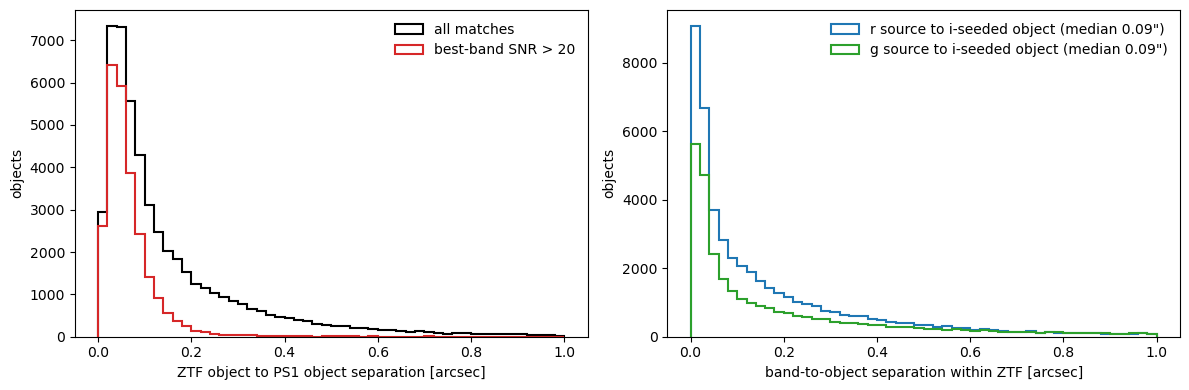

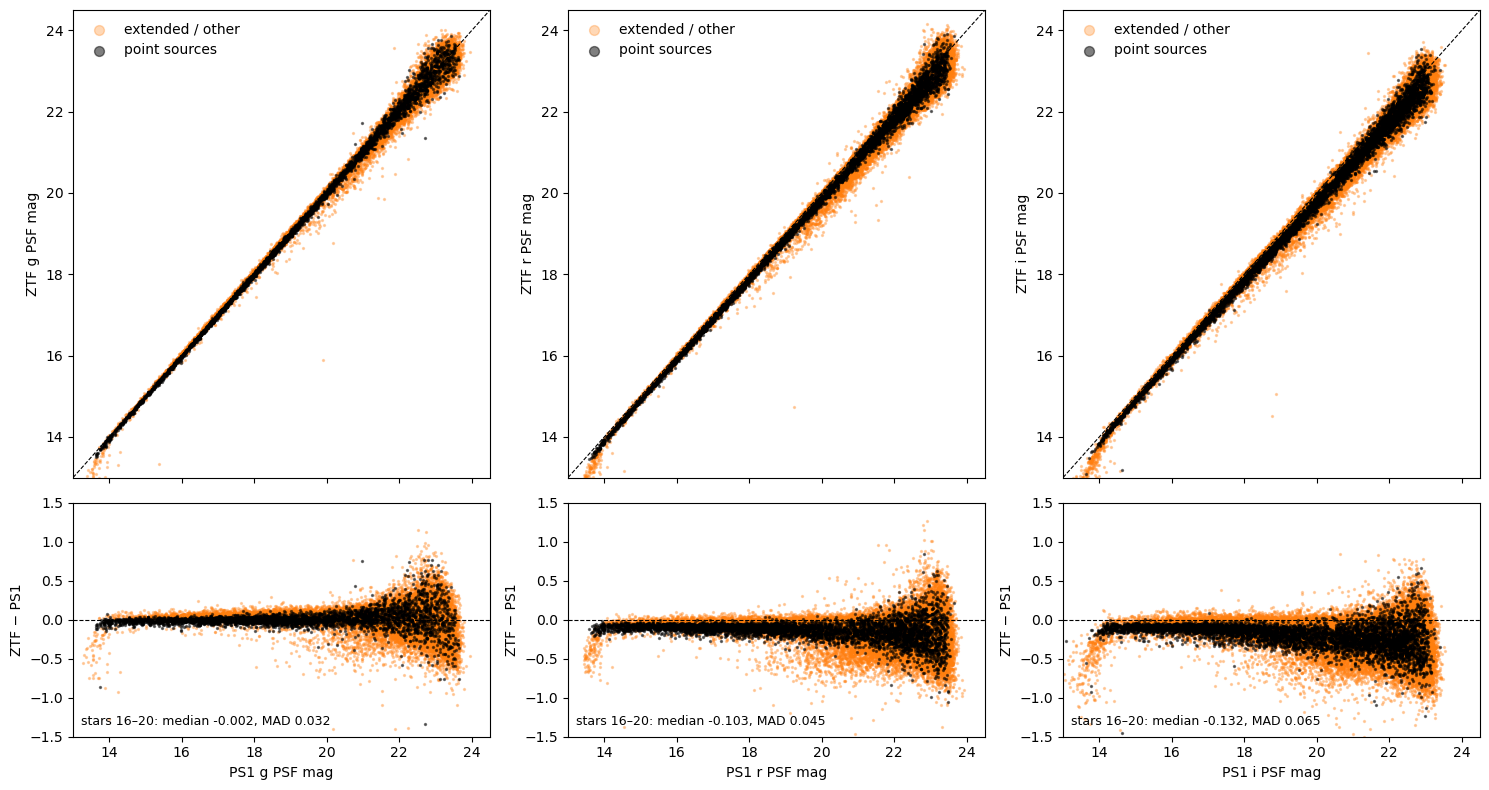

In [3]:
matched = obj[obj.matched]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 51)
axes[0].hist(matched.ps1_sep, bins=bins, histtype='step', lw=1.5, color='k', label='all matches')
axes[0].hist(matched.ps1_sep[matched.best_snr > 20], bins=bins, histtype='step', lw=1.5, color='C3', label='best-band SNR > 20')
axes[0].set_xlabel('ZTF object to PS1 object separation [arcsec]'); axes[0].set_ylabel('objects'); axes[0].legend(frameon=False)
for b, c in zip('rg', ['C0', 'C2']):
    s = obj[f'{b}_sep'].dropna()
    axes[1].hist(s, bins=bins, histtype='step', lw=1.5, color=c, label=f'{b} source to i-seeded object (median {s.median():.2f}")')
axes[1].set_xlabel('band-to-object separation within ZTF [arcsec]'); axes[1].set_ylabel('objects'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex='col', gridspec_kw={'height_ratios': [2, 1]})
for j, b in enumerate('gri'):
    m = matched[matched[f'{b}_idx'] >= 0]
    x, y = m[f'ps1_{b}_psf'], m[f'{b}_mag']; star = (m[f'ps1_{b}_psf'] - m[f'ps1_{b}_kron']).abs() < 0.05
    lim = (13, 24.5)
    axes[0, j].scatter(x[~star], y[~star], s=2, alpha=0.3, color='C1', label='extended / other')
    axes[0, j].scatter(x[star], y[star], s=2, alpha=0.5, color='k', label='point sources')
    axes[0, j].plot(lim, lim, 'k--', lw=0.8); axes[0, j].set_xlim(lim); axes[0, j].set_ylim(lim)
    axes[0, j].set_ylabel(f'ZTF {b} PSF mag'); axes[0, j].legend(frameon=False, loc='upper left', markerscale=5)
    d = y - x
    axes[1, j].scatter(x[~star], d[~star], s=2, alpha=0.3, color='C1'); axes[1, j].scatter(x[star], d[star], s=2, alpha=0.5, color='k')
    axes[1, j].axhline(0, color='k', lw=0.8, ls='--'); axes[1, j].set_ylim(-1.5, 1.5)
    axes[1, j].set_xlabel(f'PS1 {b} PSF mag'); axes[1, j].set_ylabel('ZTF − PS1')
    sel = star & (x > 16) & (x < 20)
    axes[1, j].text(0.02, 0.05, f'stars 16–20: median {d[sel].median():+.3f}, MAD {1.4826*np.median(np.abs(d[sel]-d[sel].median())):.3f}', transform=axes[1, j].transAxes, fontsize=9)
plt.tight_layout(); plt.show()

## 3. The filters

Each filter is a function of a table returning a keep-mask. ZTF filters read the DAOPhot columns of the merged object table; PS1 filters read the DR2 flag columns. Bit values are from the archive's flag pages. Variability, transient, QSO and extended-source bits are not cut here; they are kept for after filtering.

In [4]:
SNR_MIN = 5.0
NAN_RADIUS_PS1_PX = 5                                  # original association: PS1 sources within 5 px of a masked ZTF pixel were dropped
BAD_STACK, SUSPECT_STACK = 128, 64                     # qualityFlag
DEFECT, PEAK_ON_SPIKE, SATSTAR = 2048, 1 << 29, 128     # infoFlag
ON_STARCORE, ON_BURNTOOL, SATSTAR_PROFILE = 16, 32, 4096   # infoFlag2

def has_bit(col, bit):
    return (col.fillna(0).astype('int64') & bit) != 0

# ---- ZTF (per detected band) ----
def ztf_flags_ok(df):
    """DAOPhot flags == 0 in every detected band (the only non-zero value seen is 1: masked pixels in the 5x5 box)."""
    return ~np.any([(df[f'{b}_idx'] >= 0) & (df[f'{b}_flags'] != 0) for b in 'gri'], axis=0)

def ztf_n_snr_bands(df):
    return sum(((df[f'{b}_snr'] >= SNR_MIN).fillna(False)).astype(int) for b in 'gri')

def ztf_snr_1band(df): return (ztf_n_snr_bands(df) >= 1).values
def ztf_snr_2bands(df): return (ztf_n_snr_bands(df) >= 2).values

ZTF_FILTERS = {'flags == 0 in every detected band': ztf_flags_ok,
               f'SNR >= {SNR_MIN:.0f} in >= 1 band': ztf_snr_1band,
               f'SNR >= {SNR_MIN:.0f} in >= 2 bands': ztf_snr_2bands}

# ---- PS1 (per measured band) ----
def _ps1_any_band(df, flag_col, bits):
    out = np.zeros(len(df), bool)
    for b in 'gri':
        measured = df[f'{b}PSFMag'].notna()
        for bit in bits:
            out |= measured & has_bit(df[f'{b}{flag_col}'], bit)
    return out

def ps1_not_near_masked(df): return min_nan_distance(df.ra.values, df.dec.values) > NAN_RADIUS_PS1_PX
def ps1_stack_ok(df): return ~(has_bit(df.qualityFlag, BAD_STACK) | has_bit(df.qualityFlag, SUSPECT_STACK)).values
def ps1_no_defect(df): return ~_ps1_any_band(df, 'infoFlag', [DEFECT])
def ps1_no_spike(df): return ~_ps1_any_band(df, 'infoFlag', [PEAK_ON_SPIKE])
def ps1_no_starcore(df): return ~_ps1_any_band(df, 'infoFlag2', [ON_STARCORE, ON_BURNTOOL])
def ps1_not_saturated(df): return ~(_ps1_any_band(df, 'infoFlag', [SATSTAR]) | _ps1_any_band(df, 'infoFlag2', [SATSTAR_PROFILE]))

def ps1_n_snr_bands(df):
    return pd.DataFrame({b: 1.0857 / df[f'{b}PSFMagErr'] >= SNR_MIN for b in 'gri'}).sum(axis=1)

def ps1_snr_1band(df): return (ps1_n_snr_bands(df) >= 1).values
def ps1_snr_2bands(df): return (ps1_n_snr_bands(df) >= 2).values

PS1_FILTERS = {f'not within {NAN_RADIUS_PS1_PX} px of a masked ZTF pixel': ps1_not_near_masked,
               'not BAD_STACK / SUSPECT_STACK': ps1_stack_ok,
               'not DEFECT': ps1_no_defect,
               'not PEAK_ON_SPIKE': ps1_no_spike,
               'not ON_STARCORE / ON_BURNTOOL': ps1_no_starcore,
               'not SATSTAR / SATSTAR_PROFILE': ps1_not_saturated,
               f'SNR >= {SNR_MIN:.0f} in >= 1 band': ps1_snr_1band,
               f'SNR >= {SNR_MIN:.0f} in >= 2 bands': ps1_snr_2bands}

## 4. PS1-only objects

### 4.1 Waterfall

step                                              objects       r<19
all                                                  7410        101
not within 5 px of a masked ZTF pixel                6597         53
not BAD_STACK / SUSPECT_STACK                        1123         17
not DEFECT                                           1085         17
not PEAK_ON_SPIKE                                    1082         17
not ON_STARCORE / ON_BURNTOOL                        1076         16
not SATSTAR / SATSTAR_PROFILE                        1069         16
SNR >= 5 in >= 1 band                                1040         16
SNR >= 5 in >= 2 bands                                272         14


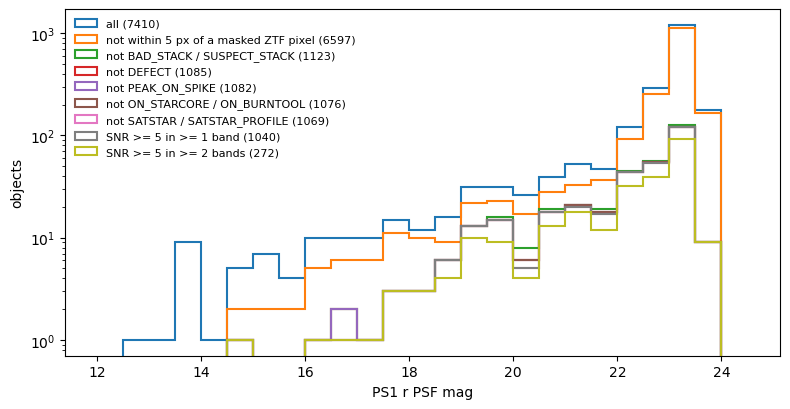

In [5]:
ps1_only = ps1[~ps1.matched].copy()
ps1_masks = waterfall(ps1_only, PS1_FILTERS, extra=(ps1_only.rPSFMag < 19).values, extra_label='r<19')
ps1_only_clean = ps1_only[ps1_masks[f'SNR >= {SNR_MIN:.0f} in >= 1 band']]    # the 2-band line is shown for reference only
mag_hist(ps1_only, ps1_masks, ps1_only.rPSFMag, 'PS1 r PSF mag')

### 4.2 What each cut removes

Four objects at random removed by each cut, among those that passed the cuts before it. ZTF r on top, PS1 r below; the cross is the object.

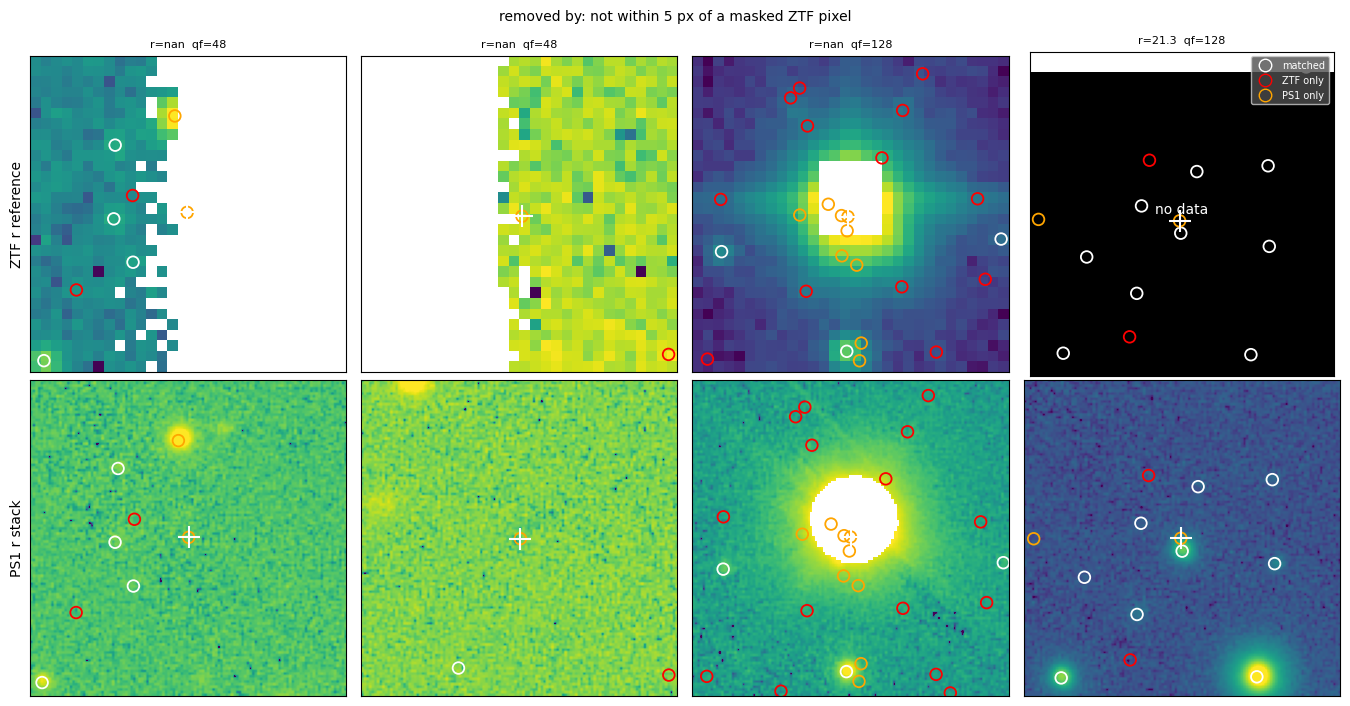

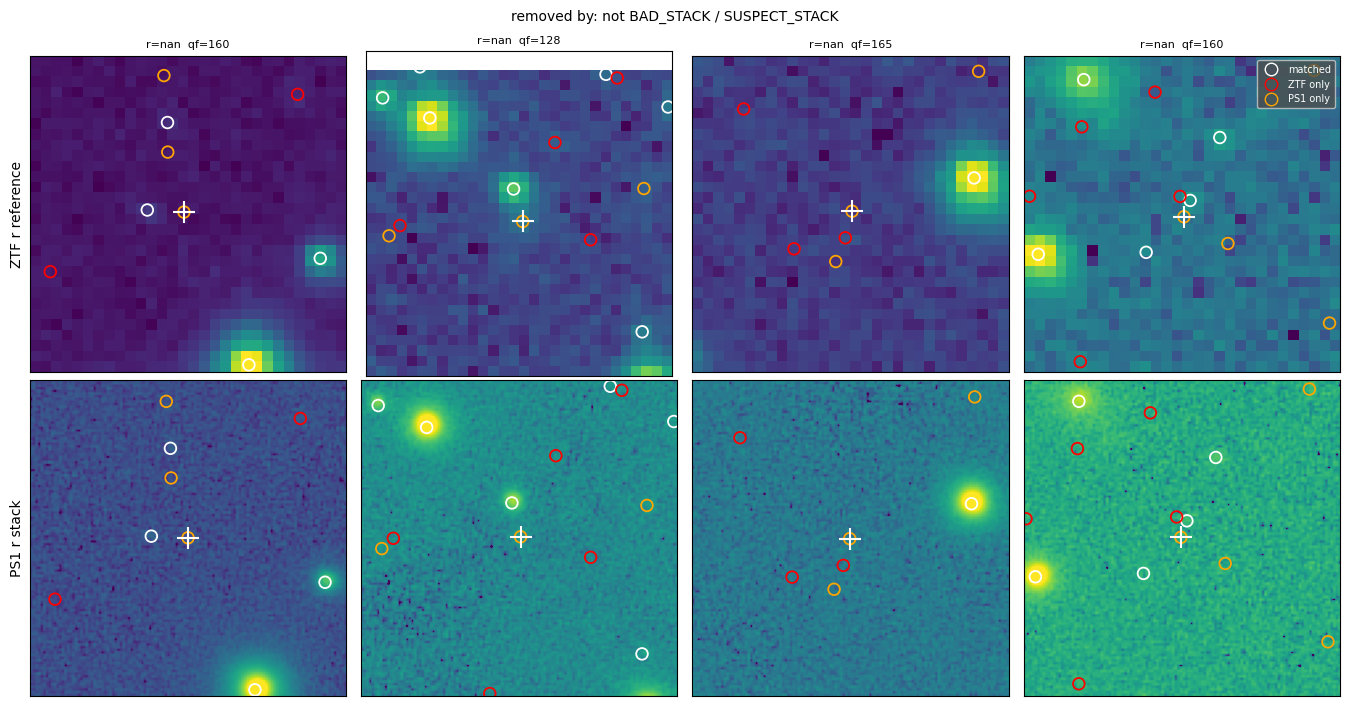

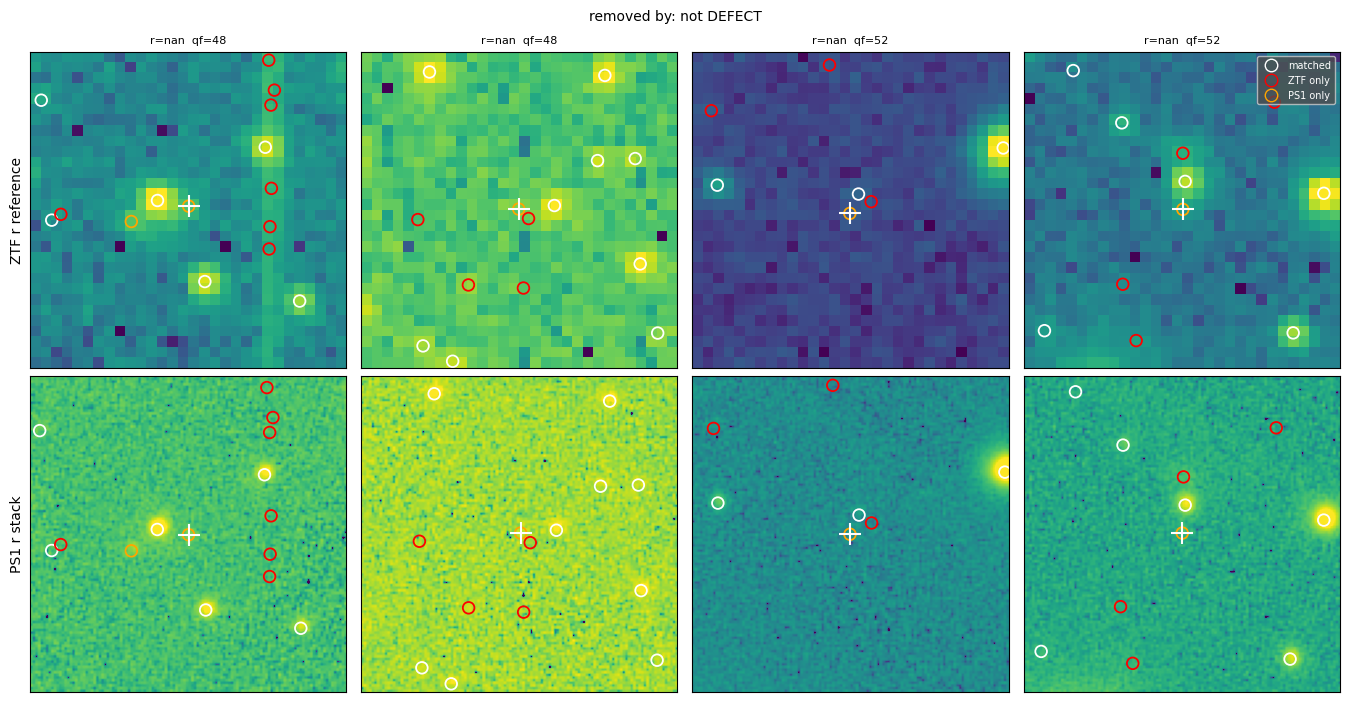

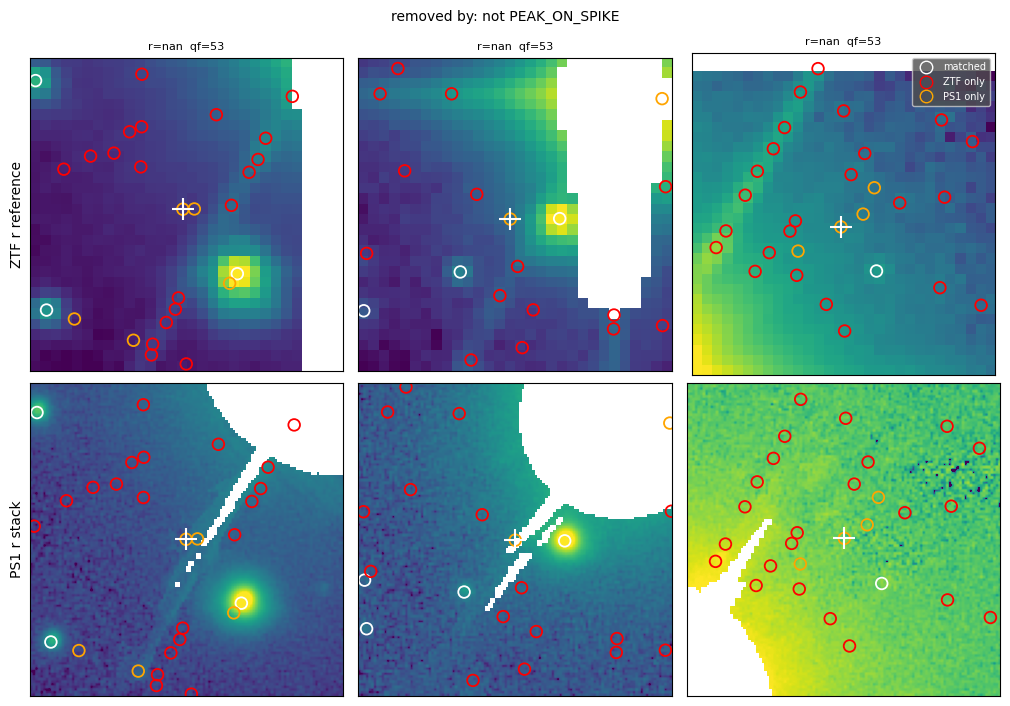

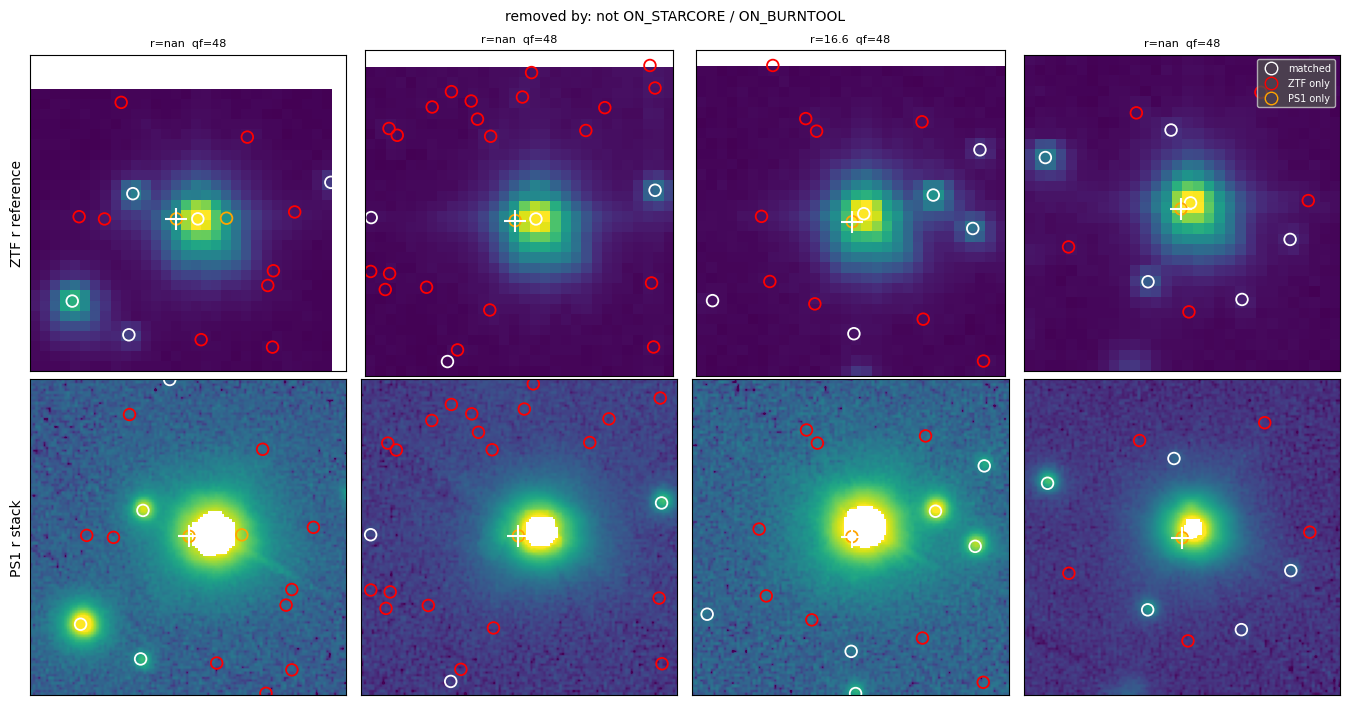

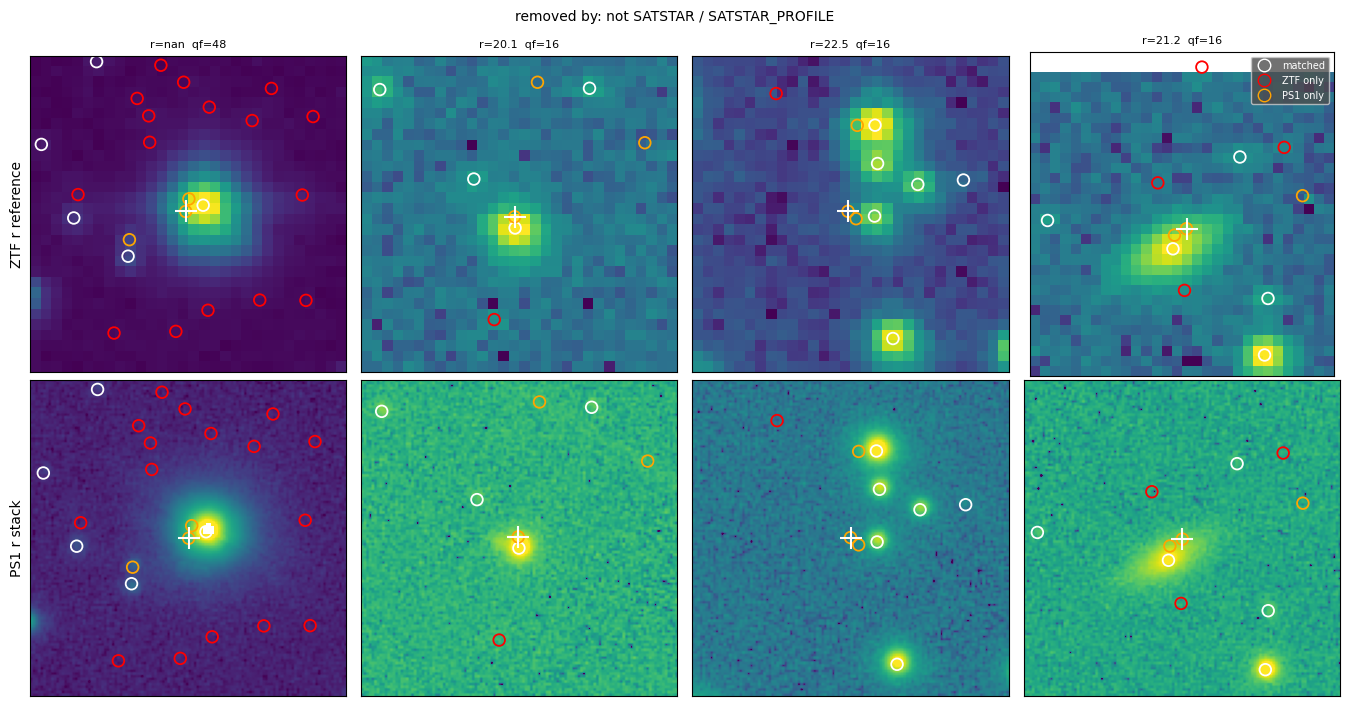

In [6]:
for label in list(PS1_FILTERS)[:-2]:   # the SNR cuts remove faint objects by construction
    ex = removed_examples(ps1_only, PS1_FILTERS, label)
    if len(ex) == 0:
        print(f'{label}: removes nothing beyond the earlier cuts'); continue
    cutout_grid([(r.ra, r.dec, f'r={r.rPSFMag:.1f}  qf={int(r.qualityFlag)}') for r in ex.itertuples()], title=f'removed by: {label}')

### 4.3 Are the survivors blend components?

Distance from each surviving PS1-only object to the nearest other PS1 object, and whether that neighbour is the one ZTF matched.

  radius  has neighbour  neighbour matched  r<19 with neighbour
    1.0"       33 (  3%)                 28            2 / 16
    2.0"      198 ( 19%)                169            7 / 16
    3.0"      441 ( 42%)                398           14 / 16
    5.0"      785 ( 75%)                705           15 / 16


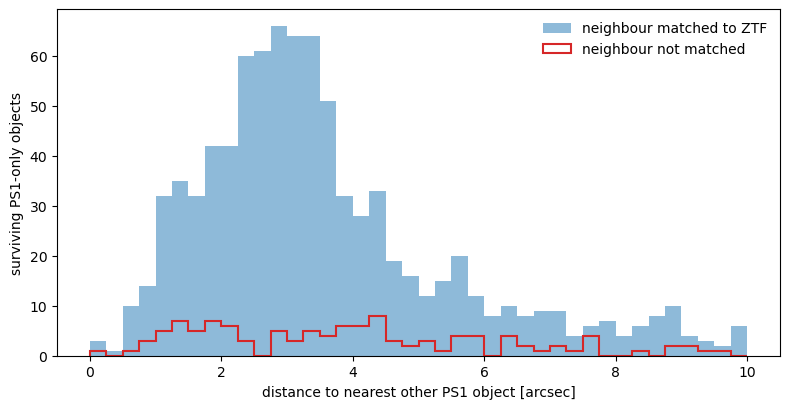

In [7]:
surv = ps1_only_clean
d, i = cKDTree(np.c_[ps1.ra.values * cosd, ps1.dec.values]).query(np.c_[surv.ra.values * cosd, surv.dec.values], k=2)
d_other, j_other = d[:, 1] * 3600, i[:, 1]
neighbour_matched = ps1.matched.values[j_other]
print(f'{"radius":>8s} {"has neighbour":>14s} {"neighbour matched":>18s} {"r<19 with neighbour":>20s}')
for r in (1.0, 2.0, 3.0, 5.0):
    near = d_other < r
    print(f'{r:7.1f}" {near.sum():8d} ({100*near.mean():3.0f}%) {(near & neighbour_matched).sum():18d} {(near & (surv.rPSFMag < 19).values).sum():12d} / {(surv.rPSFMag < 19).sum()}')
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.arange(0, 10.25, 0.25)
ax.hist(d_other[neighbour_matched], bins=bins, histtype='stepfilled', alpha=0.5, color='C0', label='neighbour matched to ZTF')
ax.hist(d_other[~neighbour_matched], bins=bins, histtype='step', lw=1.5, color='C3', label='neighbour not matched')
ax.set_xlabel('distance to nearest other PS1 object [arcsec]'); ax.set_ylabel('surviving PS1-only objects'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. ZTF-only objects

### 5.1 Waterfall

step                                              objects bestSNR>10
all                                                 48490        862
flags == 0 in every detected band                   48205        846
SNR >= 5 in >= 1 band                               14938        846
SNR >= 5 in >= 2 bands                               2155        363


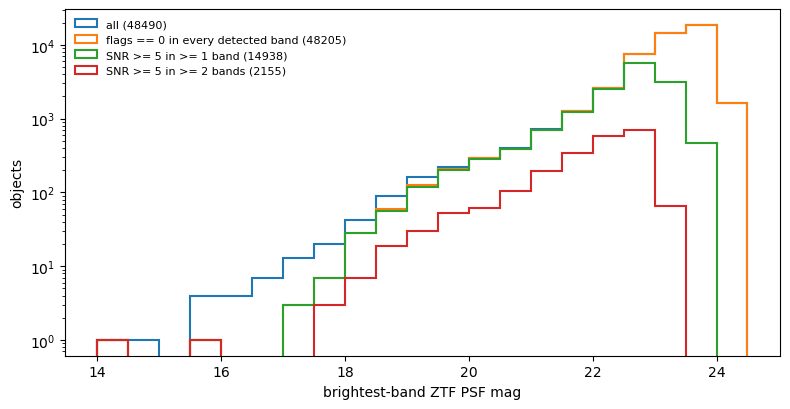

In [8]:
ztf_only = obj[~obj.matched].copy()
ztf_masks = waterfall(ztf_only, ZTF_FILTERS, extra=(ztf_only.best_snr > 10).values, extra_label='bestSNR>10')
ztf_only_clean = ztf_only[ztf_masks[f'SNR >= {SNR_MIN:.0f} in >= 2 bands']]
ztf_only['best_mag'] = ztf_only[['g_mag', 'r_mag', 'i_mag']].min(axis=1)
mag_hist(ztf_only, ztf_masks, ztf_only.best_mag, 'brightest-band ZTF PSF mag', bins=np.arange(14, 25, 0.5))

### 5.2 What each cut removes

ZTF r only.

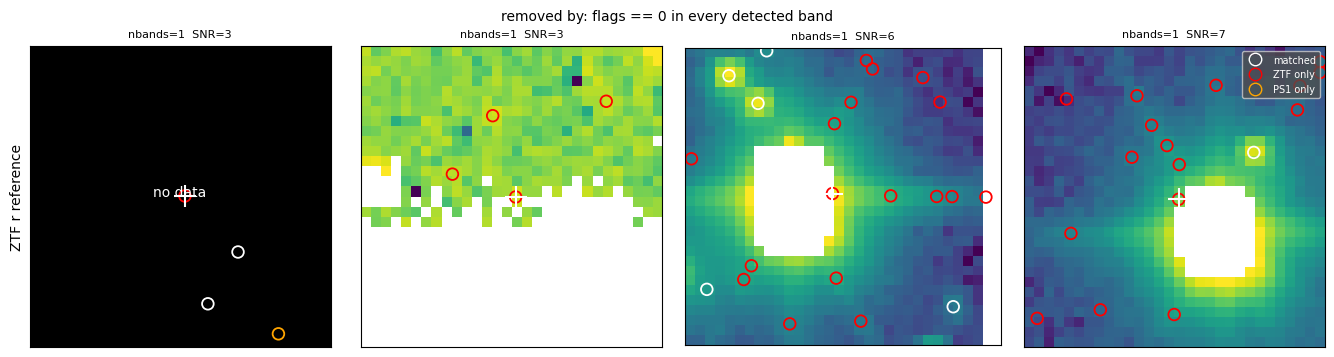

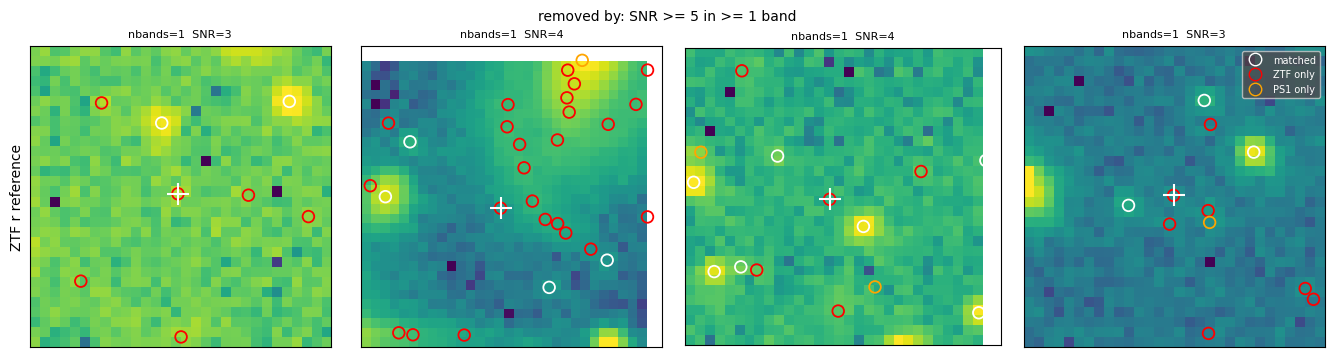

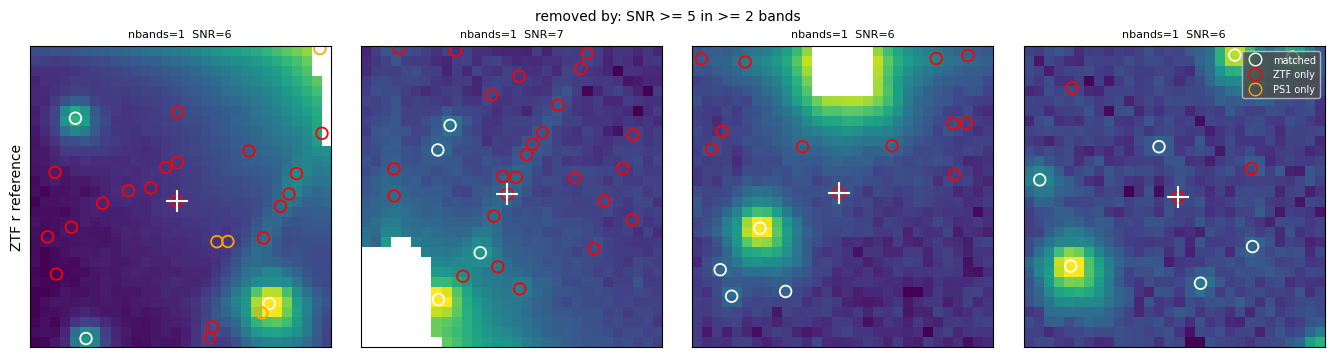

In [9]:
for label in ZTF_FILTERS:
    ex = removed_examples(ztf_only, ZTF_FILTERS, label)
    if len(ex) == 0:
        print(f'{label}: removes nothing beyond the earlier cuts'); continue
    cutout_grid([(r.ra, r.dec, f'nbands={r.nbands}  SNR={r.best_snr:.0f}') for r in ex.itertuples()], ps1_row=False, title=f'removed by: {label}')

## 6. Survivors

The four brightest and four random objects left on each side after filtering.

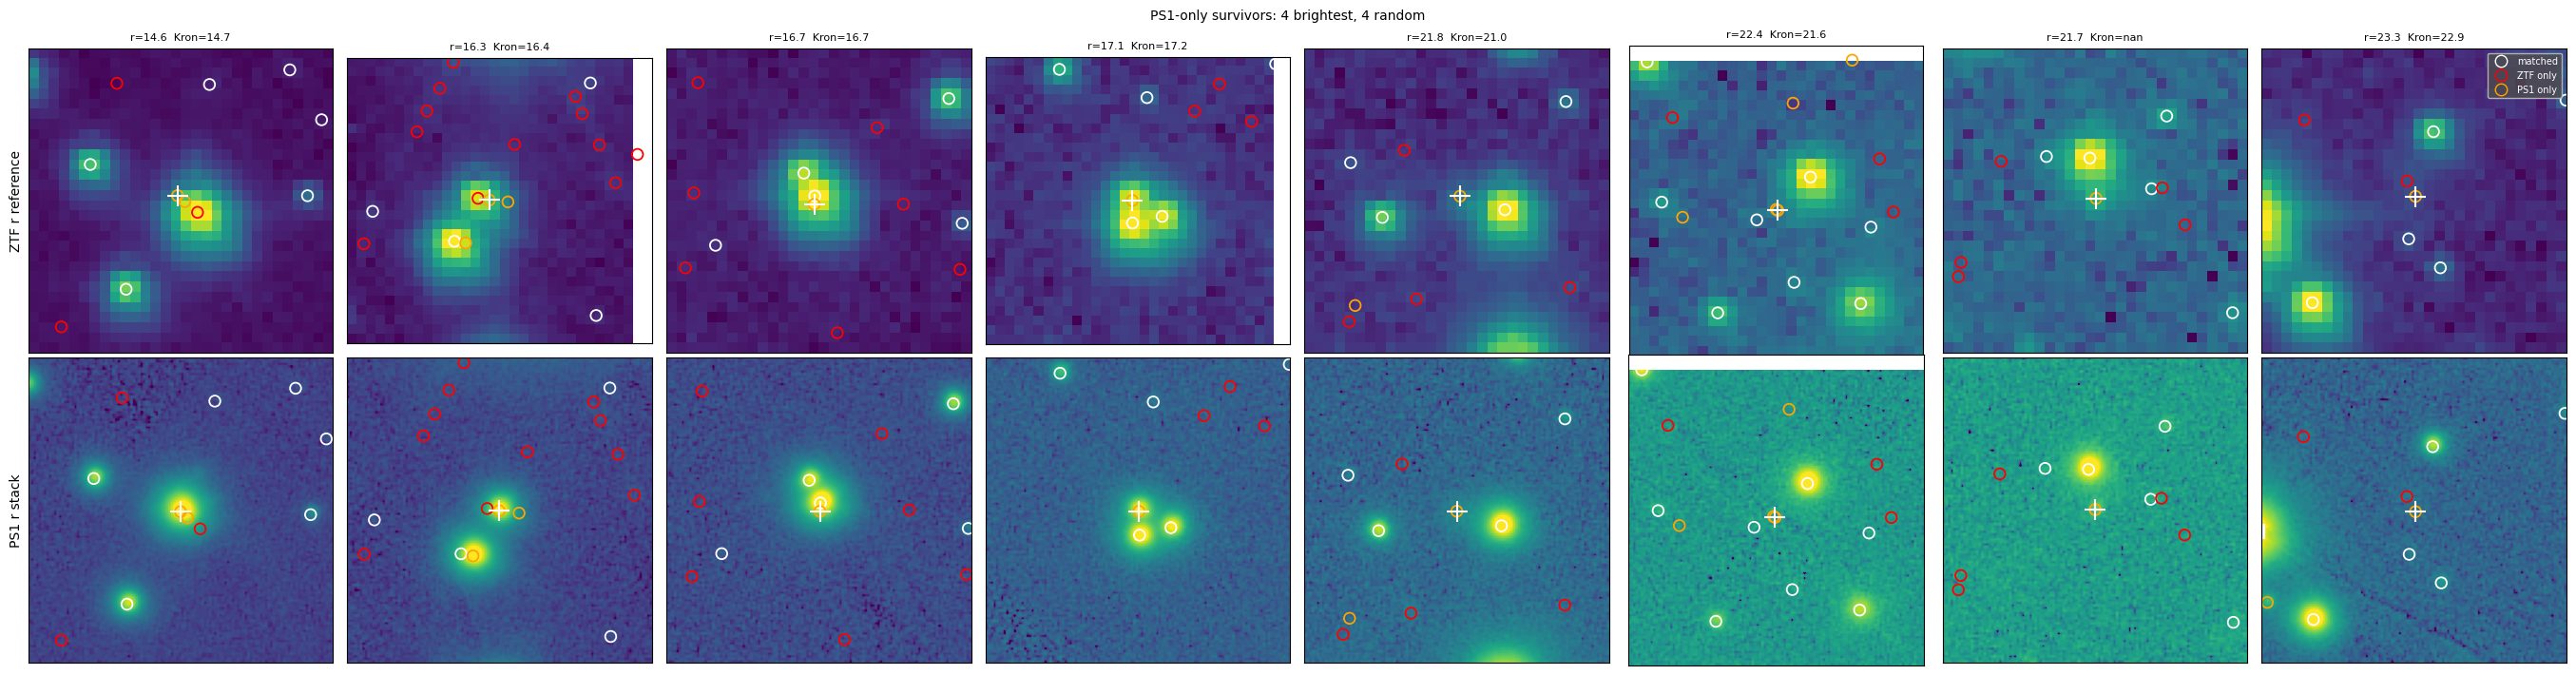

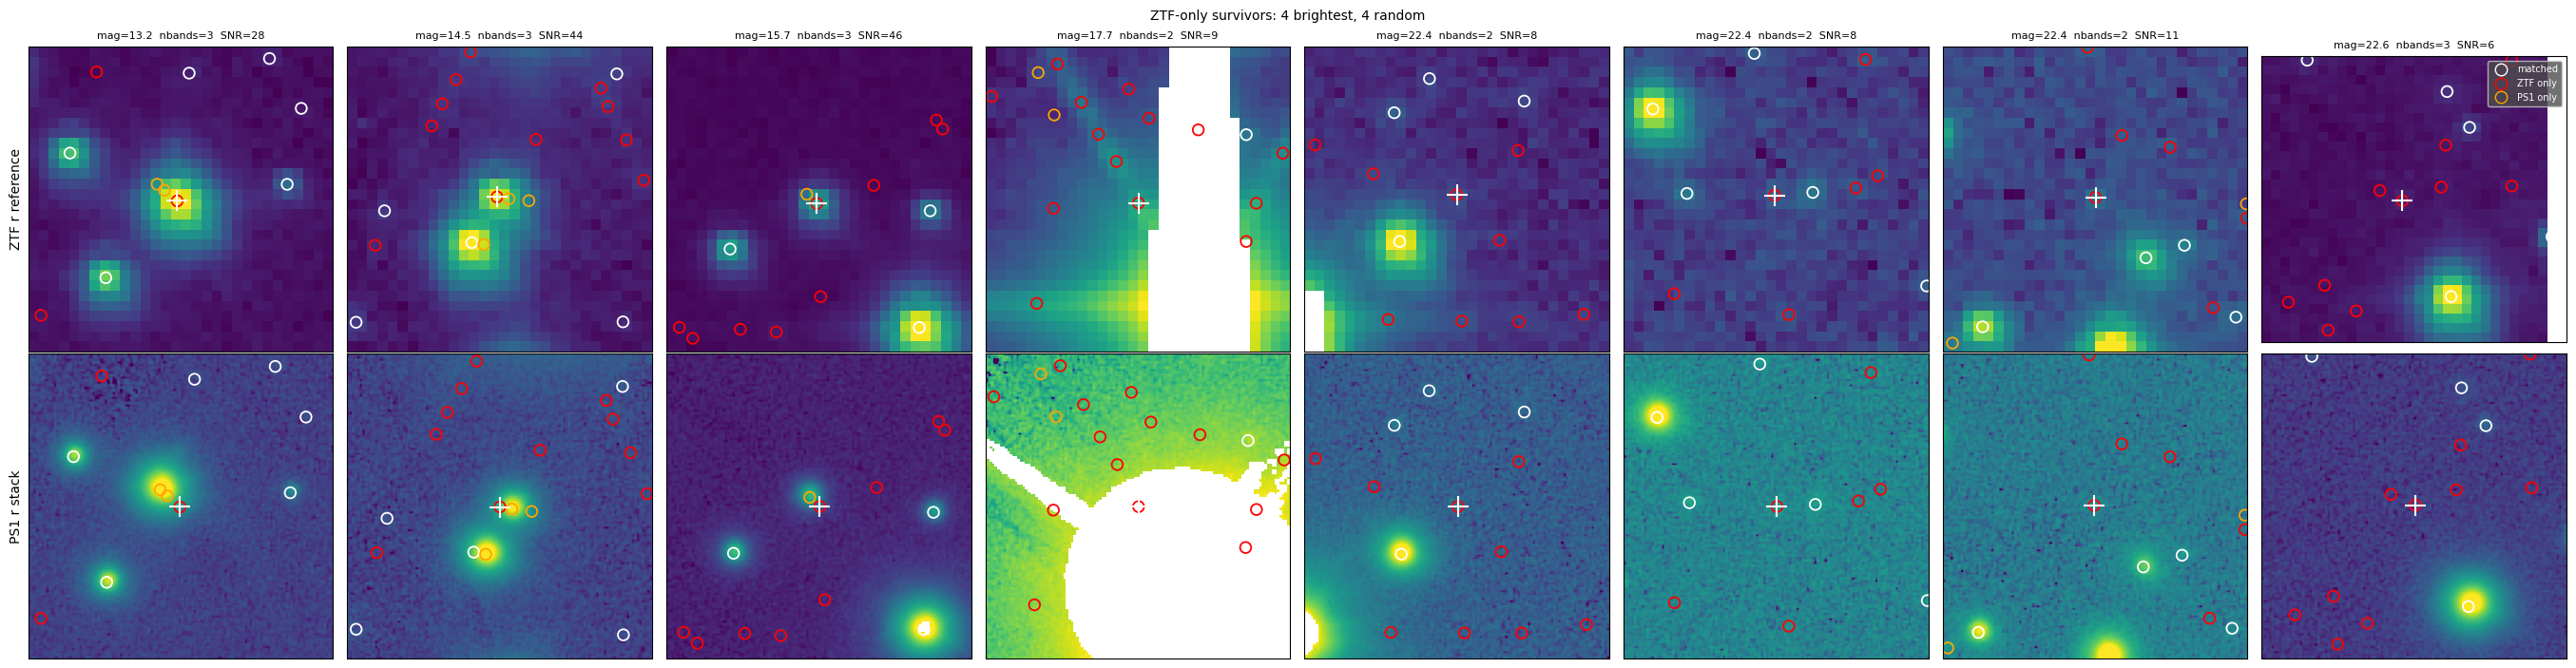

In [10]:
surv = ps1_only_clean[ps1_only_clean.rPSFMag.notna()]
top = surv.sort_values('rPSFMag').head(4); rest = surv.drop(top.index).sample(4, random_state=0)
cutout_grid([(r.ra, r.dec, f'r={r.rPSFMag:.1f}  Kron={r.rKronMag:.1f}') for r in pd.concat([top, rest]).itertuples()], title='PS1-only survivors: 4 brightest, 4 random')
surv = ztf_only_clean.copy(); surv['best_mag'] = surv[['g_mag', 'r_mag', 'i_mag']].min(axis=1)
top = surv.sort_values('best_mag').head(4); rest = surv.drop(top.index).sample(4, random_state=0)
cutout_grid([(r.ra, r.dec, f'mag={r.best_mag:.1f}  nbands={r.nbands}  SNR={r.best_snr:.0f}') for r in pd.concat([top, rest]).itertuples()], title='ZTF-only survivors: 4 brightest, 4 random')

## 7. Flowcharts

The same waterfalls drawn with the pipeline's flowchart boxes (`add_filt_from_counts` from `filter_fields`). Counts are per band: for PS1-only objects, those with a measurement in the band; for ZTF-only objects, those detected in the band. Fractions are relative to the initial counts.

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


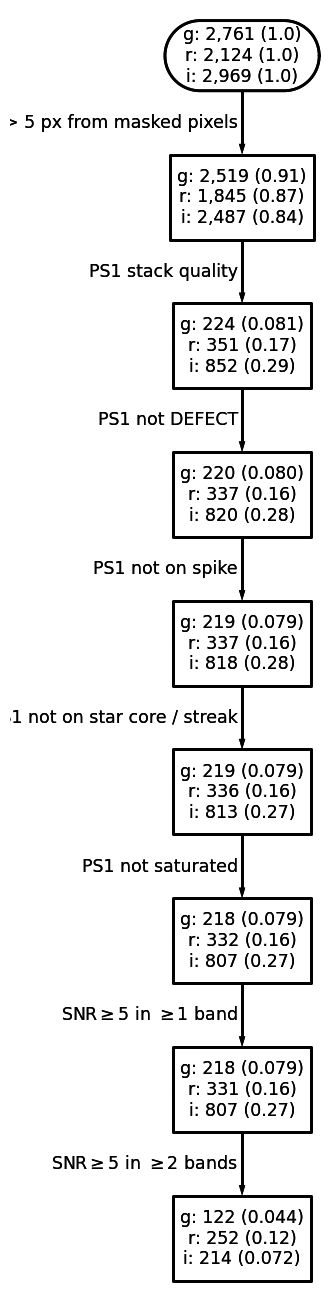

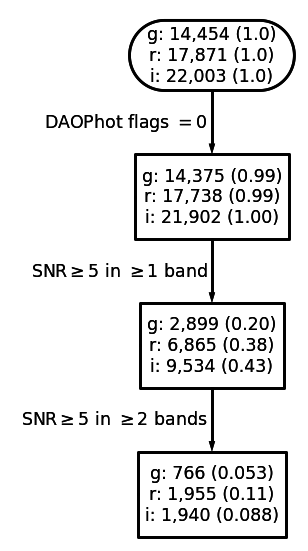

In [11]:
import schemdraw
from IPython.display import display
from Source_Analysis.filter_fields import add_filt_from_counts

CHART_LABELS = {   # shorter names for the arrows
    f'not within {NAN_RADIUS_PS1_PX} px of a masked ZTF pixel': f'> {NAN_RADIUS_PS1_PX} px from masked pixels',
    'not BAD_STACK / SUSPECT_STACK': 'PS1 stack quality',
    'not DEFECT': 'PS1 not DEFECT',
    'not PEAK_ON_SPIKE': 'PS1 not on spike',
    'not ON_STARCORE / ON_BURNTOOL': 'PS1 not on star core / streak',
    'not SATSTAR / SATSTAR_PROFILE': 'PS1 not saturated',
    'flags == 0 in every detected band': 'DAOPhot flags $= 0$',
    f'SNR >= {SNR_MIN:.0f} in >= 1 band': r'$\rm{SNR} \geq 5$ in $\geq 1$ band',
    f'SNR >= {SNR_MIN:.0f} in >= 2 bands': r'$\rm{SNR} \geq 5$ in $\geq 2$ bands',
}

def flowchart(masks, band_has, title):
    """One box per cumulative mask in `masks`; `band_has[b]` says which rows carry band b."""
    counts = lambda m: {b: int((m & band_has[b]).sum()) for b in 'gri'}
    init = pd.Series(counts(masks['all']))
    with schemdraw.Drawing(show=False) as d:
        d, prev = add_filt_from_counts(title, init.to_dict(), d, init_counts=init, start=True)
        for label, m in list(masks.items())[1:]:
            d, prev = add_filt_from_counts(CHART_LABELS.get(label, label), counts(m), d, init_counts=init, previous_element=prev)
    return d

display(flowchart(ps1_masks, {b: ps1_only[f'{b}PSFMag'].notna().values for b in 'gri'}, 'PS1-only objects'))
display(flowchart(ztf_masks, {b: (ztf_only[f'{b}_idx'] >= 0).values for b in 'gri'}, 'ZTF-only objects'))

## 8. The `in_both` sample and the envelope

Replicates the old pipeline: per band, the matched objects that pass the quality filters on both sides form the envelope sample; `build_kde_envelopes` from `filter_fields` fits a rolling KDE of ZTF − PS1 PSF magnitude in 0.5-mag windows across 14–24 (each source smoothed by its combined photometric error); `Envelope_KDE.sigma` then converts every matched object's Δmag to a signed sigma. Same cuts as sections 3–5, applied per band: ZTF `flags == 0` and SNR ≥ 5 in that band; the PS1 flag set and SNR ≥ 5 in that band.

In [12]:
from astropy.table import Table
from Source_Analysis.filter_fields import build_kde_envelopes, Envelope_KDE

def in_both_tables(objects):
    """{band: Table} in the old column schema for matched objects measured in that band on both sides, with the per-band keep-masks."""
    tabs, keep = {}, {}
    for b in 'gri':
        m = objects[objects.matched & (objects[f'{b}_idx'] >= 0) & objects[f'ps1_{b}_psf'].notna()].copy()
        p = ps1.iloc[m.ps1_idx.values]
        tab = Table({'ra': m.ra.values, 'dec': m.dec.values, 'ps1_idx': m.ps1_idx.values,
                     f'ZTF_{b}PSFMag': m[f'{b}_mag'].values, f'ZTF_{b}PSFMagErr': m[f'{b}_magerr'].values,
                     f'PSTARR_{b}PSFMag': p[f'{b}PSFMag'].values, f'PSTARR_{b}PSFMagErr': p[f'{b}PSFMagErr'].values,
                     f'PSTARR_{b}KronMag': p[f'{b}KronMag'].values, f'PSTARR_{b}KronMagErr': p[f'{b}KronMagErr'].values,
                     f'ZTF_{b}KronMag': m[f'{b}_kron'].values, f'ZTF_{b}KronMagErr': m[f'{b}_kronerr'].values,
                     'ext': ((p.qualityFlag.astype(int).values & 1) != 0)})
        ok = (m[f'{b}_flags'].values == 0) & (m[f'{b}_snr'].values >= SNR_MIN)                      # ZTF, this band
        ok &= ps1_not_near_masked(p) & ps1_stack_ok(p) & ps1_no_defect(p) & ps1_no_spike(p) & ps1_no_starcore(p) & ps1_not_saturated(p)
        ok &= (1.0857 / p[f'{b}PSFMagErr'].values) >= SNR_MIN                                      # PS1, this band
        ok = np.asarray(ok, bool)
        tabs[b], keep[b] = tab, ok
        print(f'{b}: {len(tab)} matched with both measurements, {ok.sum()} in the envelope sample')
    return tabs, keep

both_tabs, both_keep = in_both_tables(obj)
envelopes = build_kde_envelopes({b: t[both_keep[b]] for b, t in both_tabs.items()})

g: 24217 matched with both measurements, 21745 in the envelope sample
r: 38138 matched with both measurements, 34485 in the envelope sample
i: 47923 matched with both measurements, 40904 in the envelope sample


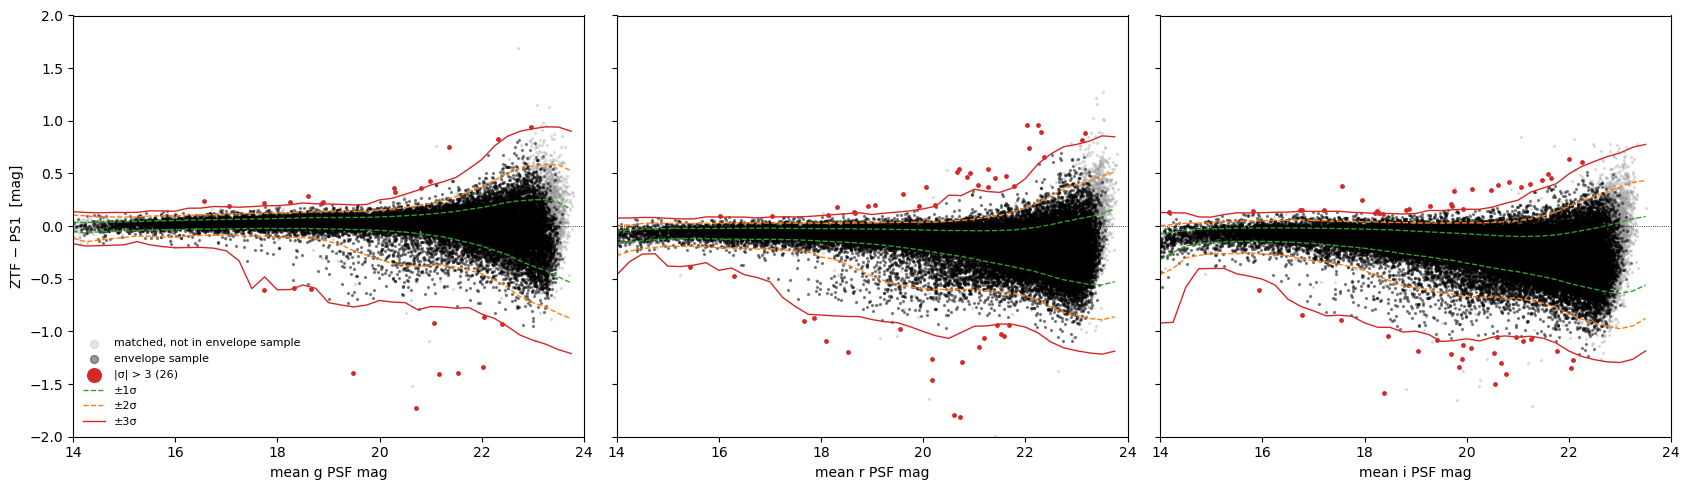

matched objects with |sigma| > 3 in >= 2 bands (any quality): 22  of 50227
same, counting only bands that pass the quality filters:    15


/var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/ipykernel_85238/1389601652.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  kp = pd.DataFrame({b: pd.Series(keep[b], index=np.asarray(t['ps1_idx'])) for b, t in tabs.items()}).fillna(False)


In [13]:
from scipy.stats import norm

def annotate_sigma(tabs, envelopes):
    """Add dmag and signed sigma (ZTF brighter = negative) to every row, as annotate_dmag_sigma does."""
    for b, t in tabs.items():
        pstarr, ztf = np.asarray(t[f'PSTARR_{b}PSFMag'], float), np.asarray(t[f'ZTF_{b}PSFMag'], float)
        t['dmag'] = ztf - pstarr
        t['sigma'], t['capped'] = envelopes[b].sigma((pstarr + ztf) / 2, t['dmag'])
        t['sigma'][pstarr <= 14.0] = np.nan
    return tabs

def envelope_plot(tabs, keep, envelopes, sample_label='envelope sample'):
    """Δmag vs mean magnitude per band, the ±1/2/3σ envelope curves, and the |σ| > 3 points among `keep`."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
    levels = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
    for ax, b in zip(axes, 'gri'):
        t, k = tabs[b], keep[b]
        mag = (np.asarray(t[f'PSTARR_{b}PSFMag']) + np.asarray(t[f'ZTF_{b}PSFMag'])) / 2
        ax.scatter(mag[~k], t['dmag'][~k], s=2, alpha=0.25, color='0.6', label=f'matched, not in {sample_label}')
        ax.scatter(mag[k], t['dmag'][k], s=2, alpha=0.4, color='k', label=sample_label)
        big = k & (np.abs(t['sigma']) > 3)
        ax.scatter(mag[big], t['dmag'][big], s=6, color='C3', label=f'|σ| > 3 ({big.sum()})')
        env = envelopes[b]; grid = env.mag_grid
        for n, c in levels:
            ax.plot(grid, env.get_percentile(grid, norm.cdf(n)), color=c, lw=1, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
        ax.axhline(0, color='k', lw=0.6, ls=':')
        ax.set_xlim(14, 24); ax.set_ylim(-2, 2); ax.set_xlabel(f'mean {b} PSF mag')
        if b == 'g': ax.set_ylabel('ZTF − PS1  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=4, loc='lower left')
    plt.tight_layout(); plt.show()

def count_candidates(tabs, keep):
    sig = pd.DataFrame({b: pd.Series(np.asarray(t['sigma']), index=np.asarray(t['ps1_idx'])) for b, t in tabs.items()})
    kp = pd.DataFrame({b: pd.Series(keep[b], index=np.asarray(t['ps1_idx'])) for b, t in tabs.items()}).fillna(False)
    print('matched objects with |sigma| > 3 in >= 2 bands (any quality):', int(((sig.abs() > 3).sum(axis=1) >= 2).sum()), ' of', len(sig))
    print('same, counting only bands that pass the quality filters:   ', int((((sig.abs() > 3) & kp).sum(axis=1) >= 2).sum()))

both_tabs = annotate_sigma(both_tabs, envelopes)
envelope_plot(both_tabs, both_keep, envelopes)
count_candidates(both_tabs, both_keep)

### 8.1 Envelope from point sources only

Same plot, but the envelope is built only from envelope-sample objects without PS1's EXT bit (`qualityFlag & 1 == 0`). Every matched object is still judged against it; red points are the |σ| > 3 objects among the *full* envelope sample, so the two figures are directly comparable.

g: 19992 point sources in the envelope sample (of 21745)
r: 31911 point sources in the envelope sample (of 34485)
i: 37952 point sources in the envelope sample (of 40904)


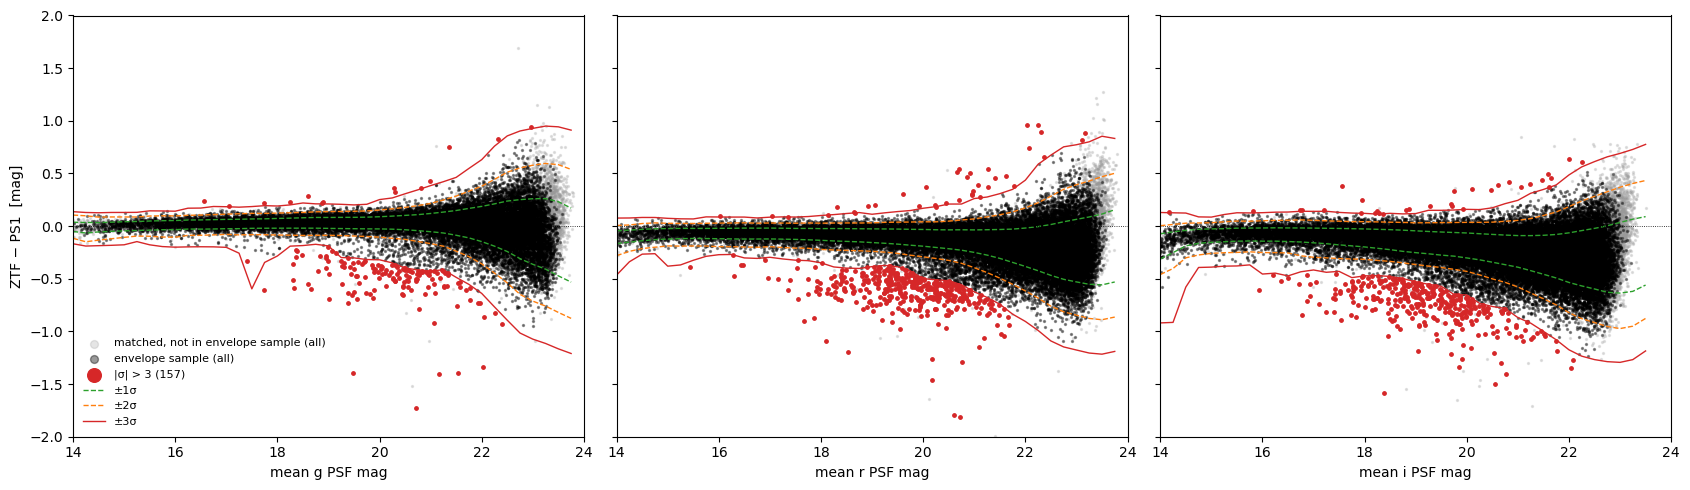

matched objects with |sigma| > 3 in >= 2 bands (any quality): 306  of 50227
same, counting only bands that pass the quality filters:    286
g: |sigma|>3 against the point-source envelope: 157, of which EXT: 131
r: |sigma|>3 against the point-source envelope: 443, of which EXT: 397
i: |sigma|>3 against the point-source envelope: 368, of which EXT: 317


/var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/ipykernel_85238/1389601652.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  kp = pd.DataFrame({b: pd.Series(keep[b], index=np.asarray(t['ps1_idx'])) for b, t in tabs.items()}).fillna(False)


In [14]:
ext_bit = (ps1.qualityFlag.astype(int).values & 1) != 0
point_keep = {b: both_keep[b] & ~ext_bit[np.asarray(both_tabs[b]['ps1_idx'])] for b in 'gri'}
for b in 'gri': print(f'{b}: {point_keep[b].sum()} point sources in the envelope sample (of {both_keep[b].sum()})')
envelopes_pt = build_kde_envelopes({b: t[point_keep[b]] for b, t in both_tabs.items()})
both_tabs_pt = annotate_sigma({b: t.copy() for b, t in both_tabs.items()}, envelopes_pt)
envelope_plot(both_tabs_pt, both_keep, envelopes_pt, sample_label='envelope sample (all)')
count_candidates(both_tabs_pt, both_keep)
ext_in_sample = {b: both_keep[b] & ext_bit[np.asarray(both_tabs[b]['ps1_idx'])] for b in 'gri'}
for b in 'gri':
    big = np.abs(both_tabs_pt[b]['sigma']) > 3
    print(f'{b}: |sigma|>3 against the point-source envelope: {int((big & both_keep[b]).sum())}, of which EXT: {int((big & ext_in_sample[b]).sum())}')

### 8.2 Point-source envelope, with extended sources coloured

Same plot as 8.1, with the envelope sample split by PS1's EXT bit instead of highlighting the |σ| > 3 points: point sources in black, extended in orange.

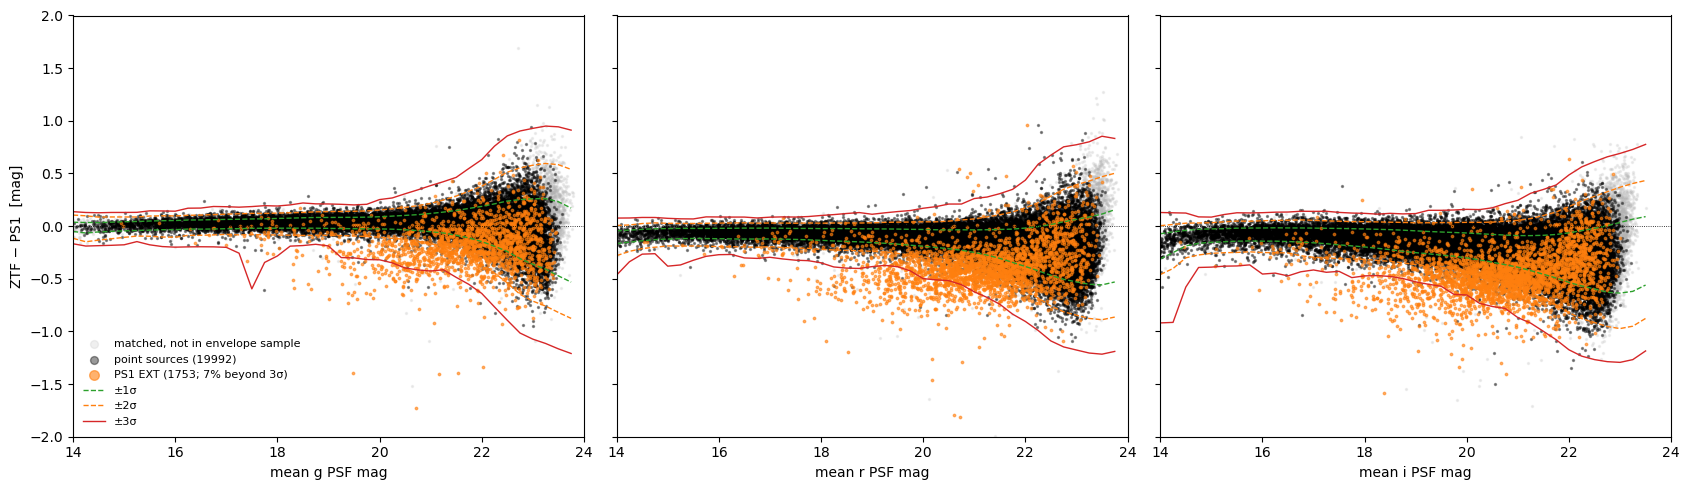

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
levels = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
for ax, b in zip(axes, 'gri'):
    t = both_tabs_pt[b]; k = both_keep[b]; e = ext_in_sample[b]
    mag = (np.asarray(t[f'PSTARR_{b}PSFMag']) + np.asarray(t[f'ZTF_{b}PSFMag'])) / 2
    ax.scatter(mag[~k], t['dmag'][~k], s=2, alpha=0.2, color='0.7', label='matched, not in envelope sample')
    ax.scatter(mag[k & ~e], t['dmag'][k & ~e], s=2, alpha=0.4, color='k', label=f'point sources ({(k & ~e).sum()})')
    ax.scatter(mag[e], t['dmag'][e], s=3, alpha=0.6, color='C1', label=f'PS1 EXT ({e.sum()}; {100*(e & (np.abs(t["sigma"]) > 3)).sum()/e.sum():.0f}% beyond 3σ)')
    env = envelopes_pt[b]; grid = env.mag_grid
    for n, c in levels:
        ax.plot(grid, env.get_percentile(grid, norm.cdf(n)), color=c, lw=1, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
    ax.axhline(0, color='k', lw=0.6, ls=':')
    ax.set_xlim(14, 24); ax.set_ylim(-2, 2); ax.set_xlabel(f'mean {b} PSF mag')
    if b == 'g': ax.set_ylabel('ZTF − PS1  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=4, loc='lower left')
plt.tight_layout(); plt.show()

## 9. Kron photometry on both sides

ZTF Kron magnitudes are SExtractor's `MAG_AUTO` from `refsexcat`, matched to the DAOPhot catalog at 1" (available for ~80–90% of DAOPhot sources above SNR 10; SExtractor's detection threshold is higher). PS1 Kron is from the catalog. Kron apertures scale with the object, not the seeing, so the extended-source offset seen in PSF photometry should largely vanish.

In [ ]:
def kron_tables(tabs):
    """Copies of the in_both tables with Kron magnitudes placed in the PSF columns, so the envelope code can run on them unchanged."""
    out = {}
    for b, t in tabs.items():
        k = t.copy()
        for side in ('ZTF', 'PSTARR'):
            k[f'{side}_{b}PSFMag'] = t[f'{side}_{b}KronMag']; k[f'{side}_{b}PSFMagErr'] = t[f'{side}_{b}KronMagErr']
        out[b] = k
    return out

kron_tabs = kron_tables(both_tabs)
has_kron = {b: both_keep[b] & np.isfinite(np.asarray(kron_tabs[b][f'ZTF_{b}PSFMag'])) & np.isfinite(np.asarray(kron_tabs[b][f'PSTARR_{b}PSFMag'])) for b in 'gri'}
ext_k = {b: np.asarray(kron_tabs[b]['ext']) for b in 'gri'}
print('PSF vs Kron differences, PS1 16-21, median and robust scatter:')
for b in 'gri':
    t, kt = both_tabs[b], kron_tabs[b]; mag = np.asarray(t[f'PSTARR_{b}PSFMag']); ok = has_kron[b] & (mag > 16) & (mag < 21)
    dp = np.asarray(t[f'ZTF_{b}PSFMag']) - np.asarray(t[f'PSTARR_{b}PSFMag']); dk = np.asarray(kt[f'ZTF_{b}PSFMag']) - np.asarray(kt[f'PSTARR_{b}PSFMag'])
    for lab, s in [('point', ok & ~ext_k[b]), ('EXT  ', ok & ext_k[b])]:
        mad = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
        print(f'  {b} {lab} n={s.sum():5d}  PSF: {np.median(dp[s]):+.3f} ± {mad(dp[s]):.3f}   Kron: {np.median(dk[s]):+.3f} ± {mad(dk[s]):.3f}')

# Kron envelope from extended sources only, and the Kron plot with EXT coloured
envelopes_kron_ext = build_kde_envelopes({b: kron_tabs[b][has_kron[b] & ext_k[b]] for b in 'gri'})
kron_tabs = annotate_sigma(kron_tabs, envelopes_kron_ext)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
levels = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
for ax, b in zip(axes, 'gri'):
    t = kron_tabs[b]; k = has_kron[b]; e = ext_k[b]
    mag = (np.asarray(t[f'PSTARR_{b}PSFMag']) + np.asarray(t[f'ZTF_{b}PSFMag'])) / 2
    ax.scatter(mag[k & ~e], t['dmag'][k & ~e], s=2, alpha=0.4, color='k', label=f'point sources ({(k & ~e).sum()})')
    ax.scatter(mag[k & e], t['dmag'][k & e], s=3, alpha=0.6, color='C1', label=f'PS1 EXT ({(k & e).sum()}; {100*(k & e & (np.abs(t["sigma"]) > 3)).sum()/(k & e).sum():.0f}% beyond 3σ)')
    env = envelopes_kron_ext[b]; grid = env.mag_grid
    for n, c in levels:
        ax.plot(grid, env.get_percentile(grid, norm.cdf(n)), color=c, lw=1, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ (EXT Kron envelope)' if n > 0 else None)
    ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2); ax.set_xlabel(f'mean {b} Kron mag')
    if b == 'g': ax.set_ylabel('ZTF − PS1 Kron  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=4, loc='lower left')
plt.tight_layout(); plt.show()

### 9.1 Morphology-split scheme

Point sources (no EXT bit) are judged on PSF Δmag against the point-source PSF envelope (8.1); extended sources on Kron Δmag against the extended-source Kron envelope above. Each object's per-band sigma comes from its own population.

In [ ]:
split_tabs = {}
for b in 'gri':
    t = both_tabs_pt[b].copy()                          # PSF dmag/sigma against the point-source envelope
    kt = kron_tabs[b]; e = ext_k[b]
    t['dmag'][e] = kt['dmag'][e]; t['sigma'][e] = kt['sigma'][e]; t['capped'][e] = kt['capped'][e]
    t['sigma'][e & ~has_kron[b]] = np.nan                # extended source with no Kron on one side: no verdict
    split_tabs[b] = t
split_keep = {b: np.where(ext_k[b], has_kron[b], both_keep[b]) for b in 'gri'}
print('--- full-sample PSF envelope (old pipeline):'); count_candidates(both_tabs, both_keep)
print('--- point-source PSF envelope for everything:'); count_candidates(both_tabs_pt, both_keep)
print('--- morphology split (PSF for point sources, Kron for extended):'); count_candidates(split_tabs, split_keep)
for b in 'gri':
    big = (np.abs(split_tabs[b]['sigma']) > 3) & split_keep[b]
    print(f'  {b}: |sigma|>3 {int(big.sum())}, of which EXT {int((big & ext_k[b]).sum())}')